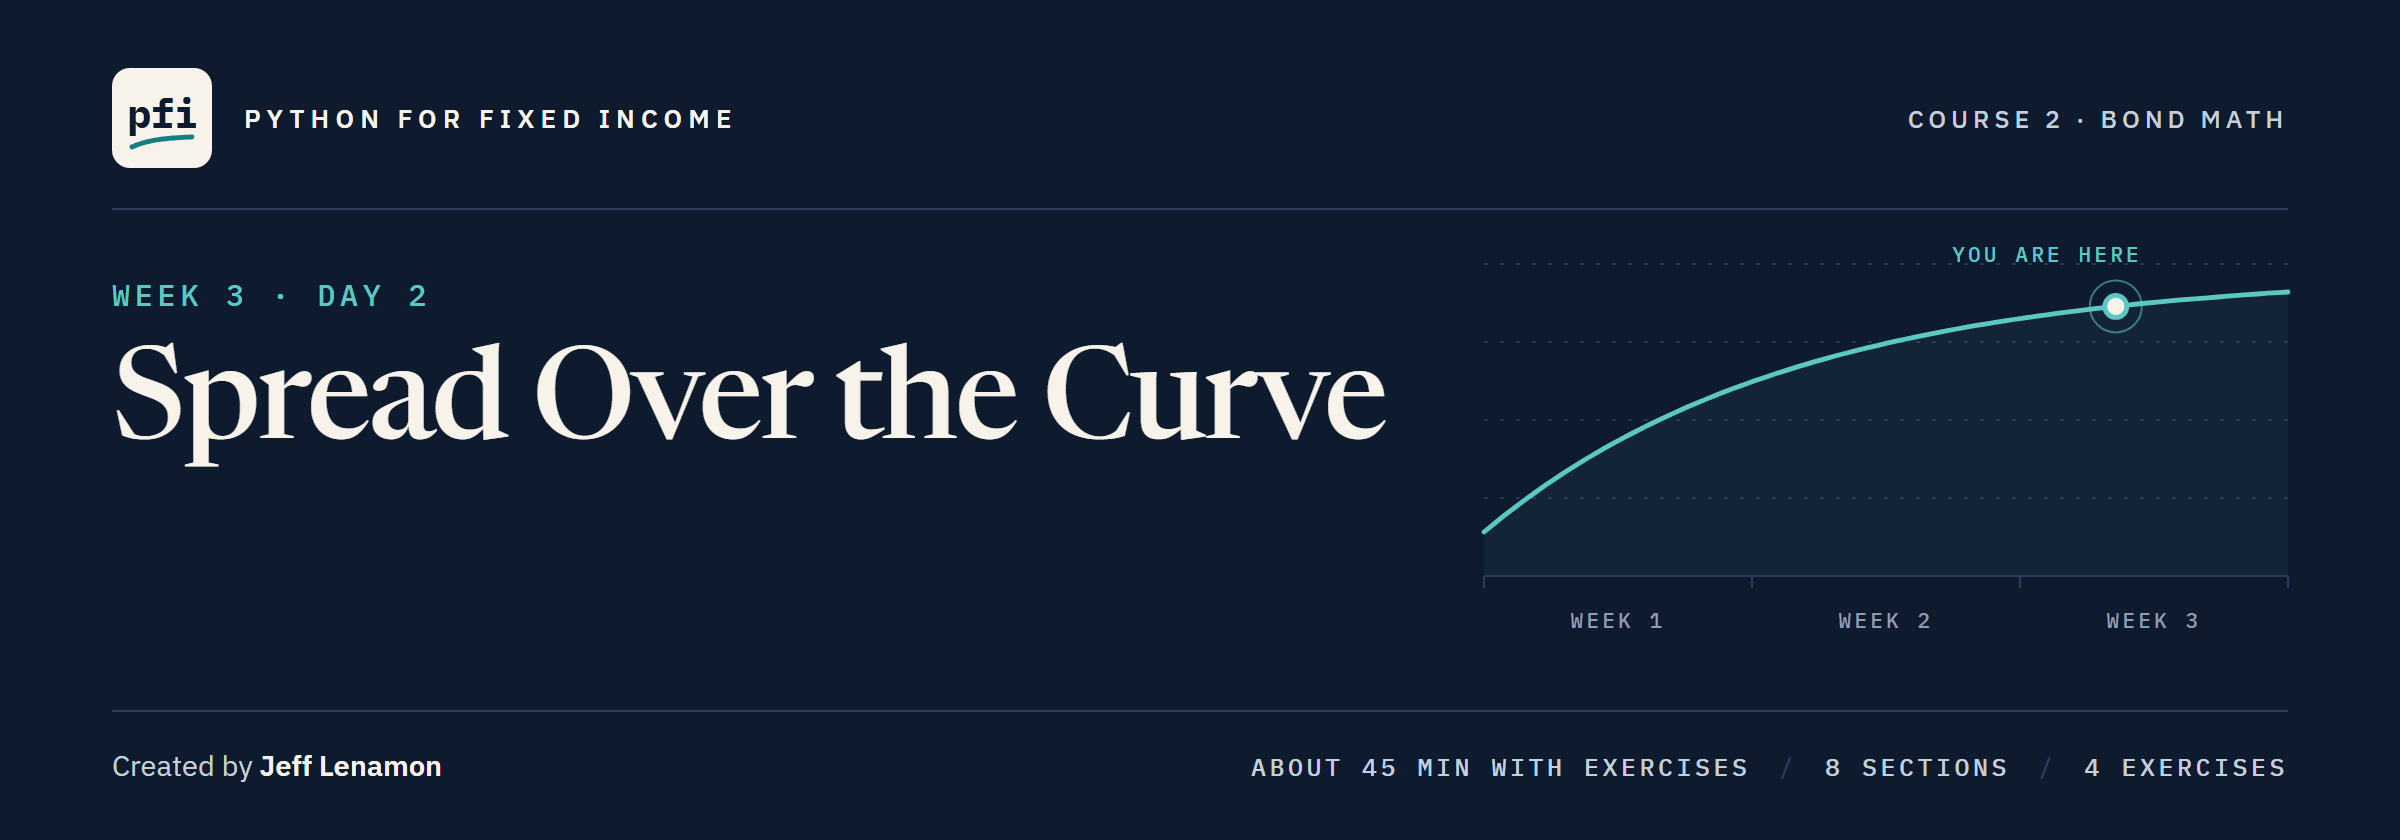

# Spread Over the Curve

Week 3, Day 2. The holdings file's `oas` column rebuilt from the curve, bond by bond, and how the reading between tenors moves a spread.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day2/12_spread_over_the_curve.ipynb)

### The Desk Lead's Note

> Our month-end file has a column called `oas`. Bezane Finance's 2032 bond shows 147. Where does that come from? Rebuild it for all 200 bonds. Then tell me whether our own ten-tenor curve gives the same spreads, and what we should call the number.

The issuers are invented; every number describes the data.

**One number on one bond first, then the whole book.**

## Your Route Through Day 2

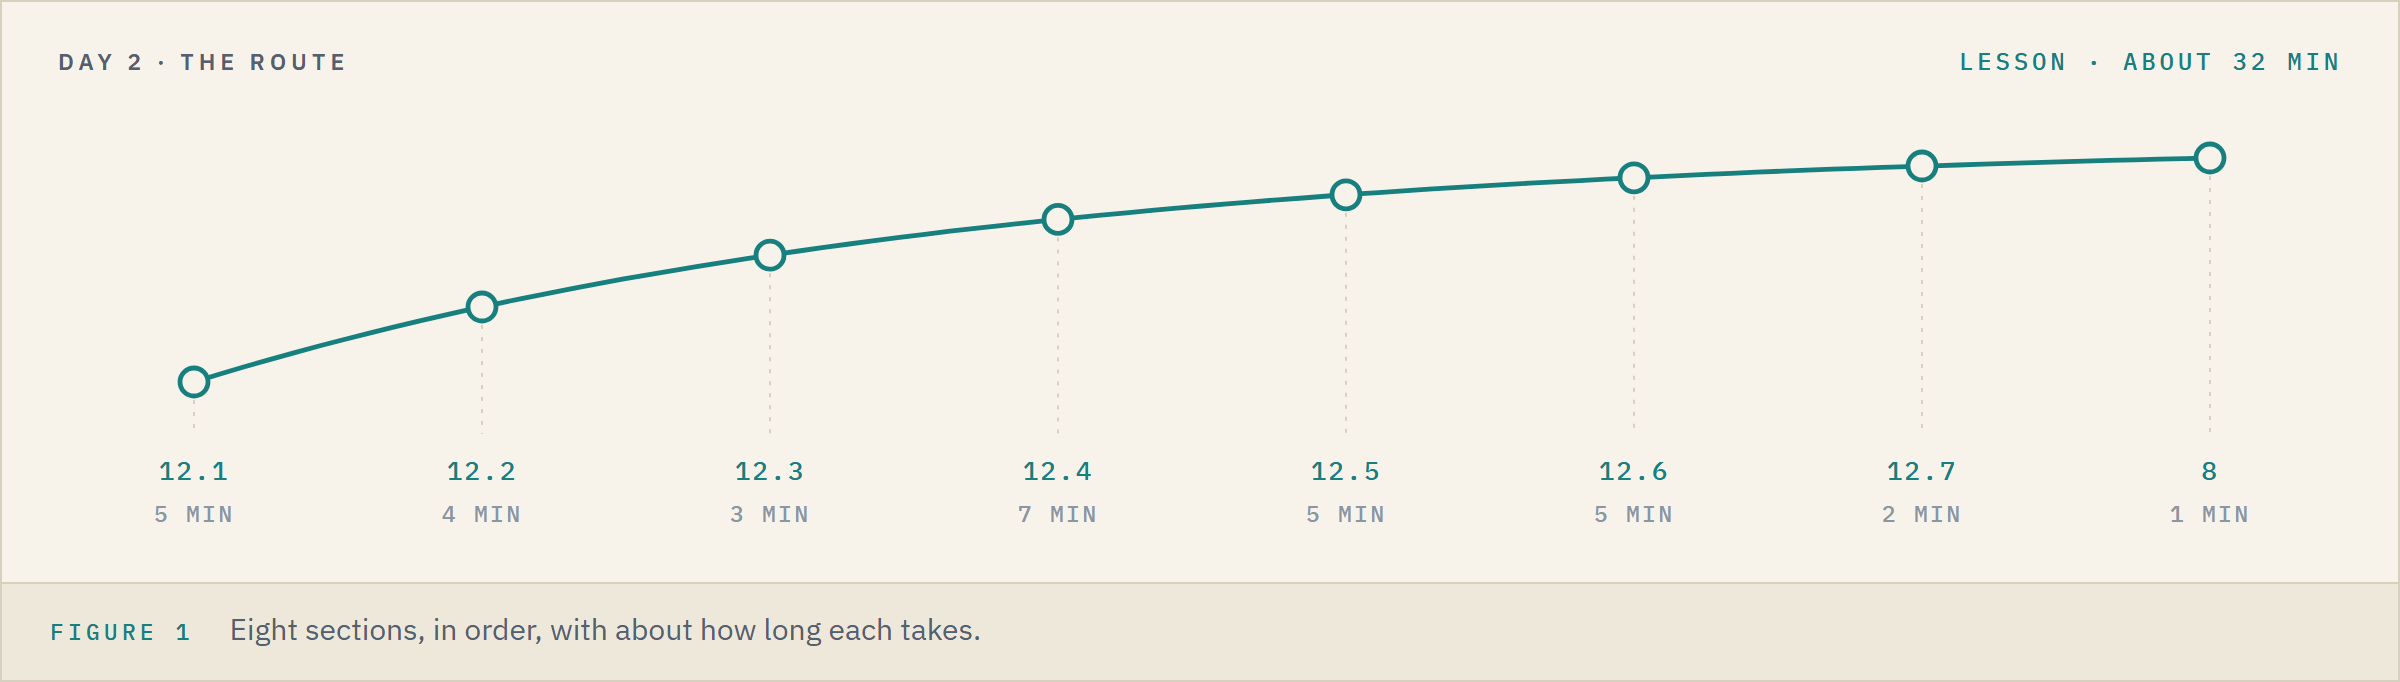

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">12.1</td><td align="left">One Bond, by Hand</td><td align="left">5 min</td></tr>
<tr><td align="left">12.2</td><td align="left">Years to Maturity, the File's Way</td><td align="left">4 min</td></tr>
<tr><td align="left">12.3</td><td align="left">The Curve at Bezane's Maturity, and 147</td><td align="left">3 min</td></tr>
<tr><td align="left">12.4</td><td align="left">Two Functions, Docstring First</td><td align="left">7 min</td></tr>
<tr><td align="left">12.5</td><td align="left">Tests From Excel, Then Commit</td><td align="left">5 min</td></tr>
<tr><td align="left">12.6</td><td align="left">The Desk's Ten-Tenor Table, and the Gap</td><td align="left">5 min</td></tr>
<tr><td align="left">12.7</td><td align="left">What to Call the Number</td><td align="left">2 min</td></tr>
<tr><td align="left">8</td><td align="left">Bring It Home</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 32 minutes for the lesson, then about 12 for the four exercises.

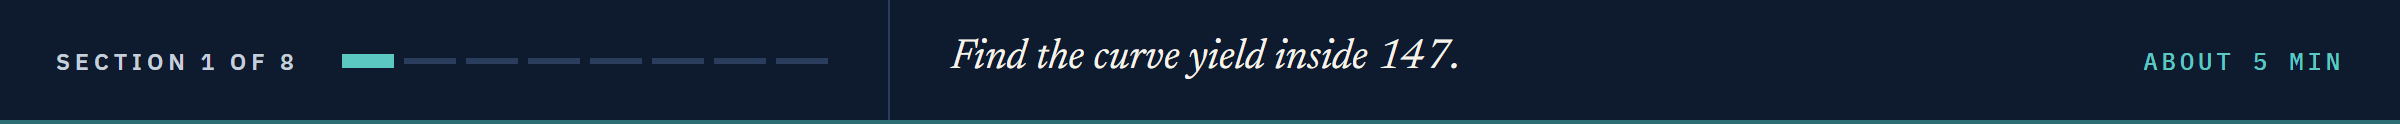

## 12.1 One Bond, by Hand

### Make Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 11 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(12)

Work folder pfi_course2_12_k4w7q2xr: 6 data files, the module as notebook 11 left it, 11 commits, tagged week1 and week2


### The Tests Pass Before We Start

Q. How many tests pass this morning?

In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

................................                                         [100%]
32 passed in 0.50s



### Import the Module and the Libraries

In [3]:
import bondmath
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

### Read the Book

`start_day` copied today's data files into the work folder, so each is read by its name.

Q. What do the first five bonds show?

In [4]:
holdings = pd.read_csv('holdings.csv')
# bondmath takes datetime.date values, as in notebook 06
holdings['as_of_date'] = pd.to_datetime(holdings['as_of_date']).dt.date
holdings['maturity'] = pd.to_datetime(holdings['maturity']).dt.date
holdings[['cusip', 'issuer', 'maturity', 'yield_pct', 'oas']].head()

,cusip,issuer,maturity,yield_pct,oas
0,99080CAE8,Bezane Finance,2032-06-18,5.606,147
1,99049XAE2,Bezamyth Machinery,2029-04-17,9.220,535
2,99039NAC0,Bezoquil Freight,2030-06-03,5.509,153
3,99039NAG1,Bezoquil Freight,2053-04-09,6.756,218
4,99034IAD4,Bezorin Finance,2036-04-05,5.600,127


### Read the Curve

Q. What does the curve file hold?

In [5]:
curve = pd.read_csv('course2_treasury_curve.csv')
# plain lists, the shape notebook 11's interpolate_yield takes
curve_tenors = curve['tenor_years'].tolist()
curve_yields = curve['yield_pct'].tolist()
print(curve_tenors)
print(curve_yields)

[0.25, 0.5, 1.0, 2.0, 3.0, 5.0, 7.0, 10.0, 20.0, 30.0]
[3.587, 3.622, 3.69, 3.811, 3.916, 4.086, 4.214, 4.348, 4.54, 4.586]


Ten tenors in years, ten yields in percent: notebook 11's invented curve.
A **spread to the curve** is the bond's yield minus the curve's yield at the same maturity.
One percent is 100 basis points, so the gap in percent times 100 is the spread in bp.

### The Curve Yield Inside 147

**Predict 1**

Q. Bezane Finance yields 5.606 percent and its `oas` says 147. What curve yield, in percent, did the file subtract? Write down a number.

In [6]:
bond = holdings.iloc[0]
# oas is in bp: divide by 100 for percent, then take it from the yield
implied_curve_pct = bond['yield_pct'] - bond['oas'] / 100
print(f"{bond['issuer']}: the file subtracted {implied_curve_pct:.3f} percent")

Bezane Finance: the file subtracted 4.136 percent


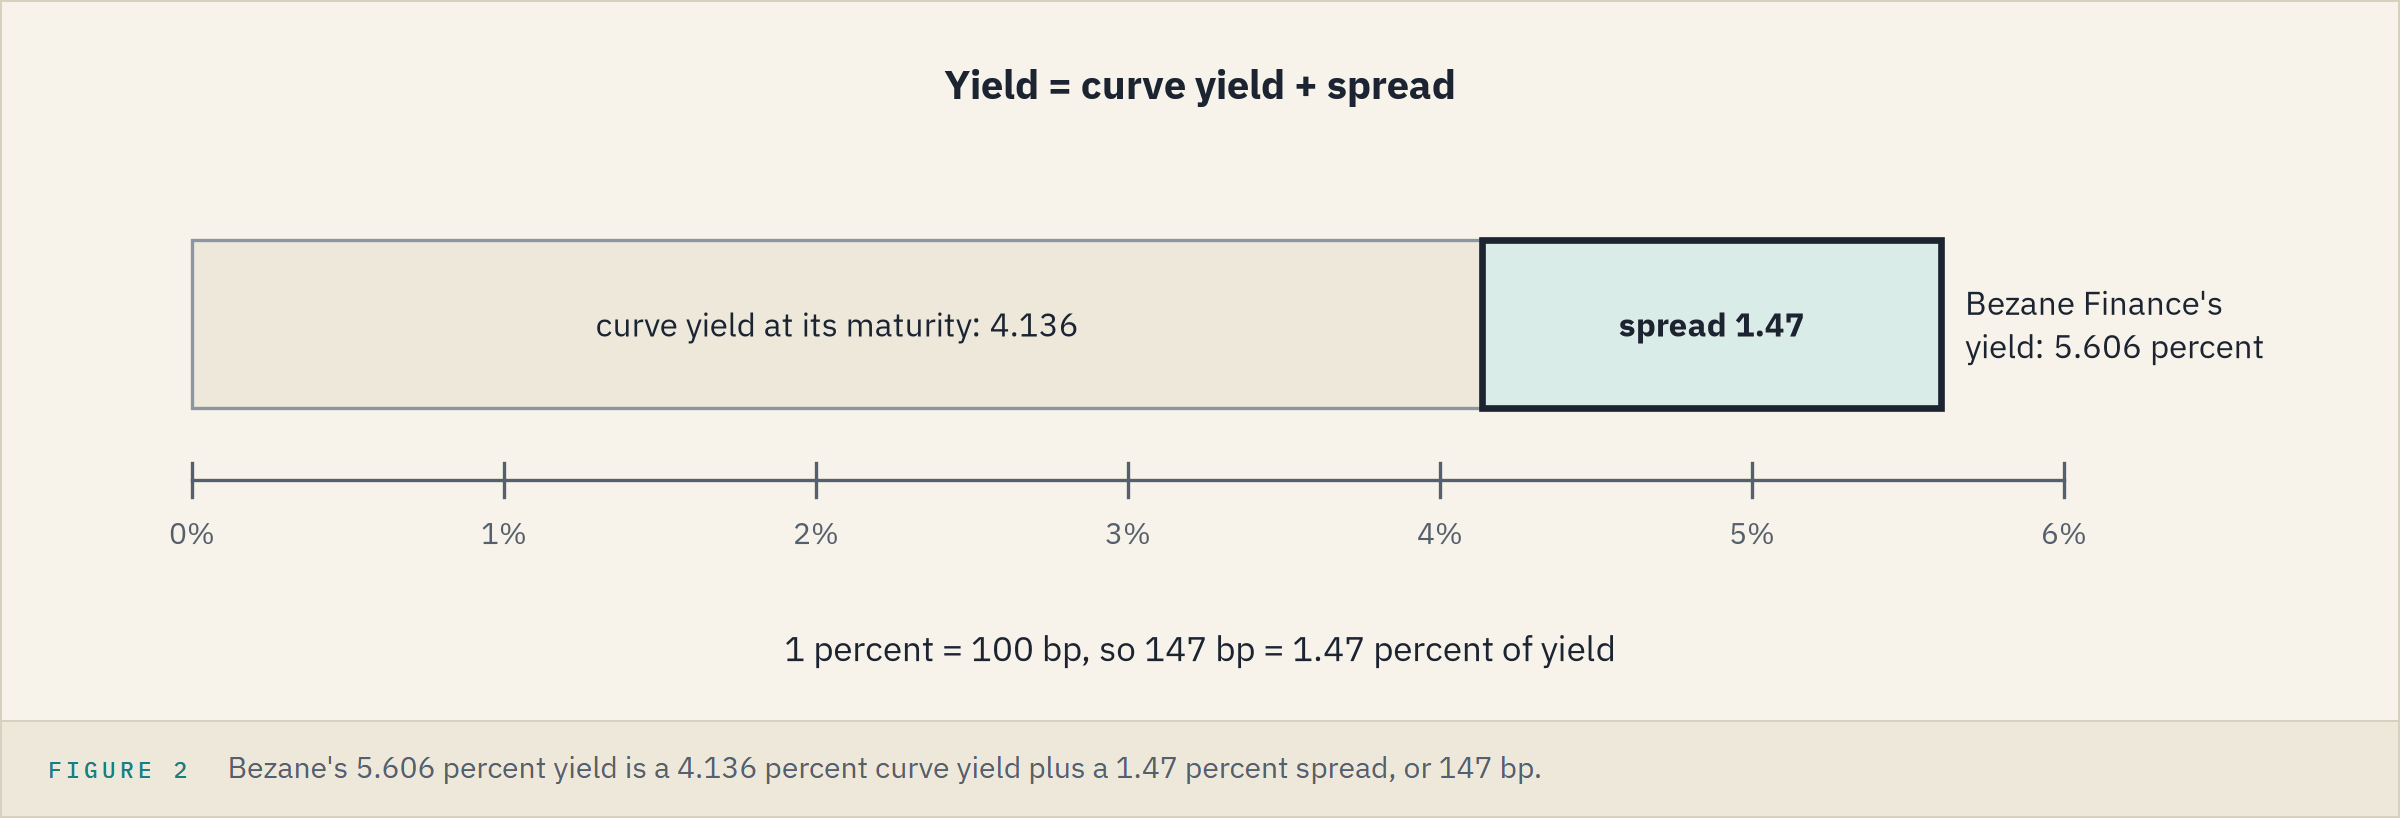

The bond matures in 2032, between the curve's 5-year point (4.086) and its 7-year point (4.214).

**147 bp is 1.47 percent of yield above a curve yield of 4.136; the day finds where 4.136 comes from.**

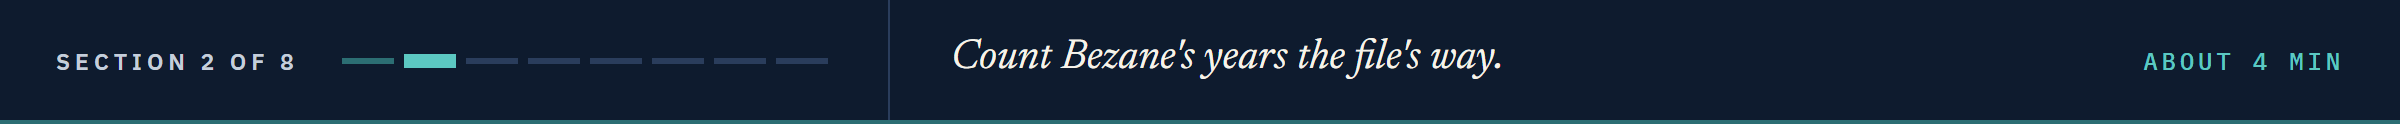

## 12.2 Years to Maturity, the File's Way

The curve's tenors are years, so each maturity has to become a number of years.
The file's own rule, in `tools/make_holdings.py`, the script that built it: the 30/360 day count from the as-of date to maturity, over 360.

### Two Ways to Count Bezane's Years

**Predict 2**

Q. Count Bezane Finance's years as actual days over 365, then as 30/360 days over 360. How far apart are the two answers?

A) about a month: two year lengths five days apart, for more than five years

B) identical: the same two dates give the same years

C) a day or two: each count is divided by its own year length

In [7]:
as_of, maturity = bond['as_of_date'], bond['maturity']
# actual calendar days, then notebook 07's 30/360 count
actual_days = (maturity - as_of).days
days_360 = bondmath.days_30_360(as_of, maturity)
print(f'actual: {actual_days} days / 365 = {actual_days / 365:.4f} years')
print(f'30/360: {days_360} days / 360 = {days_360 / 360:.4f} years')

actual: 2088 days / 365 = 5.7205 years
30/360: 2058 days / 360 = 5.7167 years


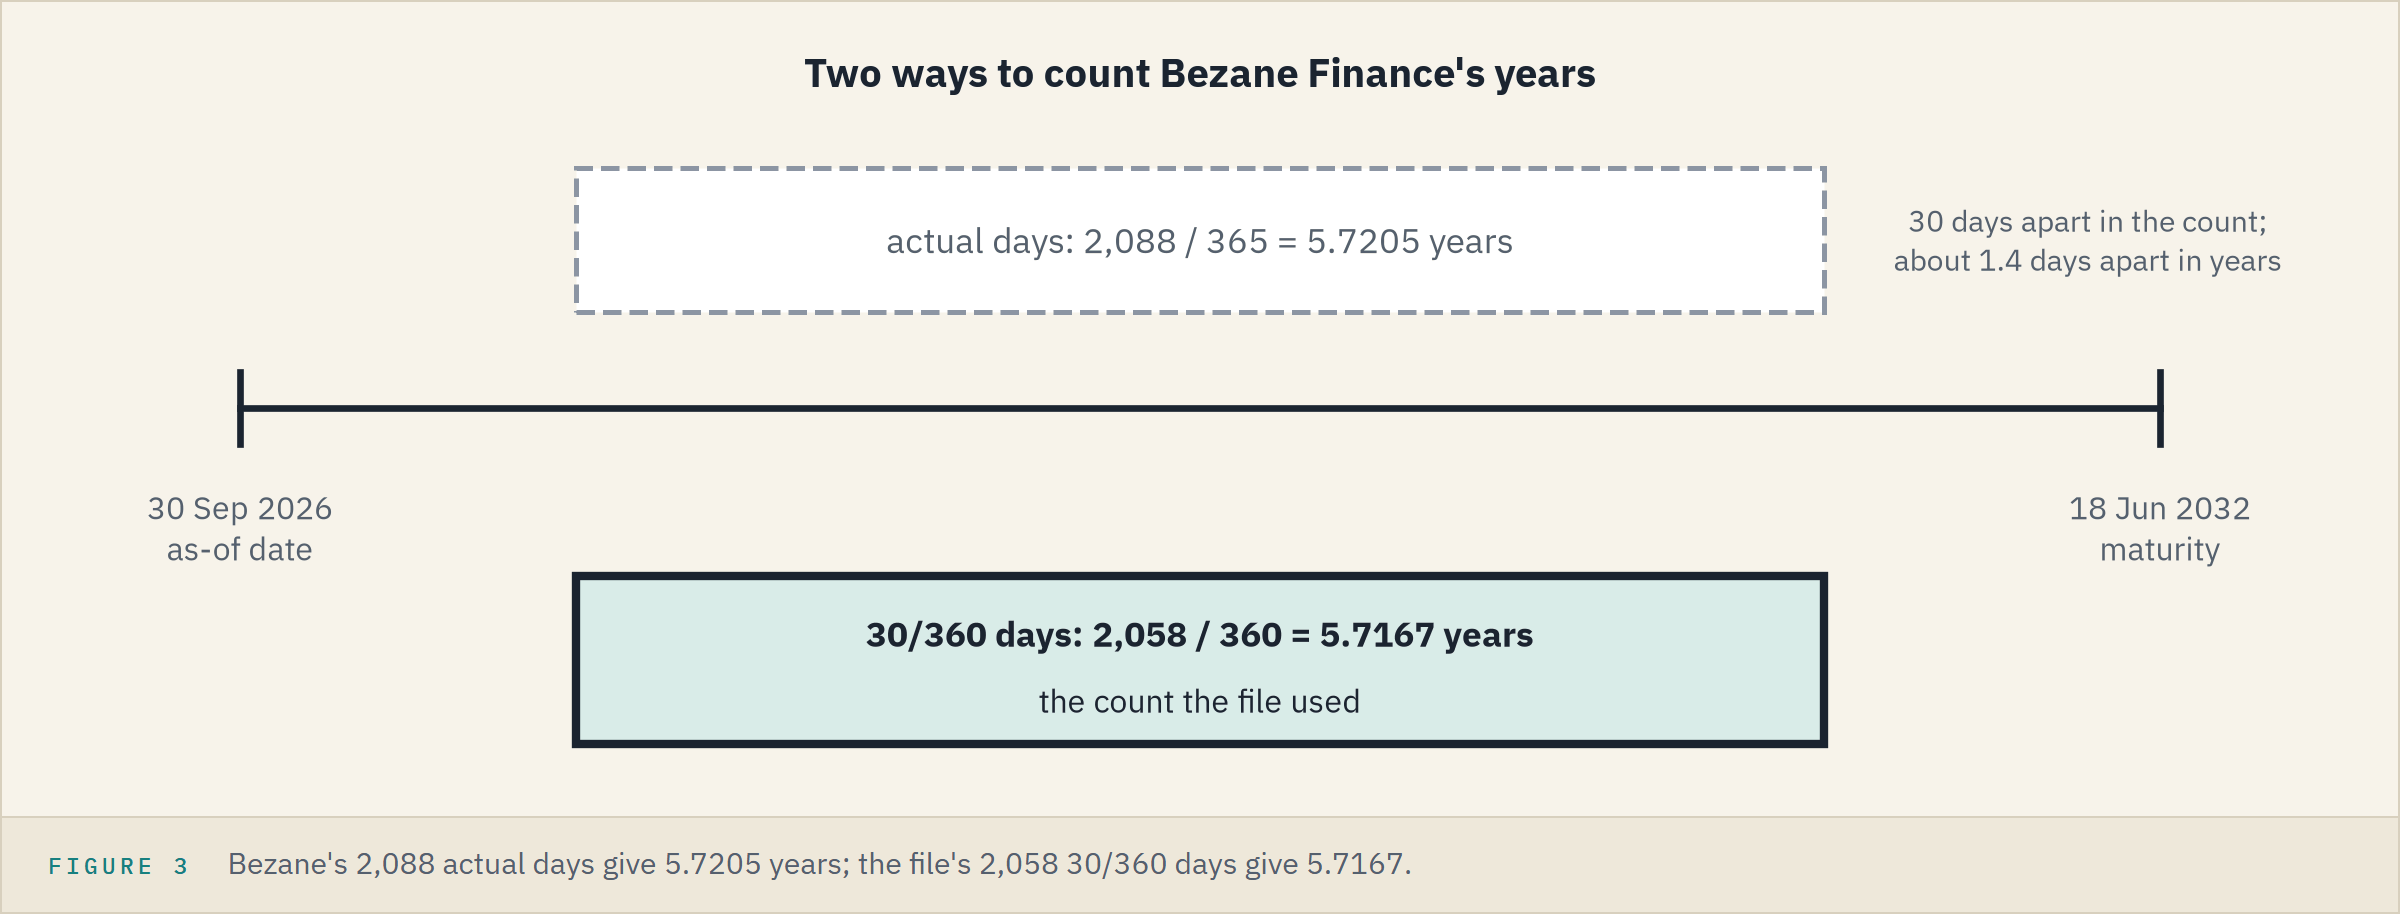

C: the counts are 30 days apart, but the years only 0.0039 apart, about 1.4 days.
Either is a fair convention; only the second reproduces the file.

### Every Bond's Years

Q. Count the years of all 200 bonds the file's way.

In [8]:
# 30/360 days over 360 for every bond, one at a time
holdings['years'] = [bondmath.days_30_360(a, m) / 360
                     for a, m in zip(holdings['as_of_date'], holdings['maturity'])]
print(f"{holdings['years'].min():.4f} to {holdings['years'].max():.4f} years")

1.0056 to 29.8972 years


### Where the Bonds Sit Against the Tenors

Q. Draw the 200 years with the curve's ten tenors dotted.

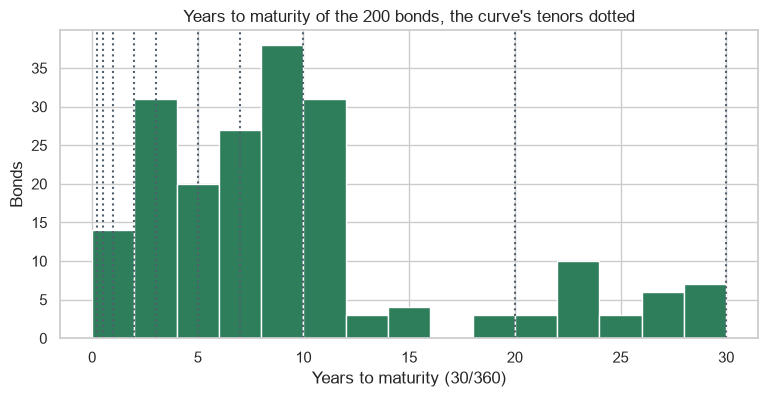

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(holdings['years'], bins=range(0, 32, 2), edgecolor='white')
# a dotted line at each of the curve's ten tenors
for tenor in curve_tenors:
    ax.axvline(tenor, color='#52606D', linestyle=':')
ax.set_title("Years to maturity of the 200 bonds, the curve's tenors dotted")
ax.set_xlabel('Years to maturity (30/360)')
ax.set_ylabel('Bonds')
plt.show()

Every bond sits inside the table, from 1 to 30 years; none falls exactly on a tenor.

**Excel side by side.** Settlement in D2, maturity in E2; filled down, `YEARFRAC` equals the Python column on all 200 bonds.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Years, 30/360</td><td align="left"><code>bondmath.days_30_360(as_of, maturity) / 360</code></td><td align="left"><code>=YEARFRAC(D2,E2,0)</code></td><td align="left">5.716666666666667</td></tr>
<tr><td align="left">The day count</td><td align="left"><code>bondmath.days_30_360(as_of, maturity)</code></td><td align="left"><code>=YEARFRAC(D2,E2,0)*360</code></td><td align="left">2058</td></tr>
<tr><td align="left">The lookalike, 28 Feb 2027 to 31 Aug 2031</td><td align="left">none</td><td align="left"><code>=DAYS360(DATE(2027,2,28),DATE(2031,8,31))</code></td><td align="left">1620, where <code>YEARFRAC</code> x 360 gives 1621</td></tr>
</table>
<br clear="left">

**Every bond sits between two tenors, so each needs the curve read between points.**

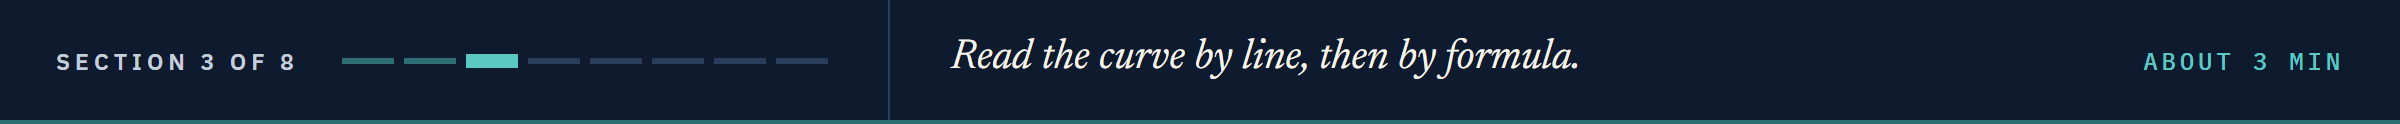

## 12.3 The Curve at Bezane's Maturity, and 147

### The Straight Line

Q. What does notebook 11's `interpolate_yield` give at Bezane's years?

In [10]:
years = holdings.loc[0, 'years']
# the straight line between the two tenors around 5.7167 years
curve_line_pct = bondmath.interpolate_yield(years, curve_tenors, curve_yields)
print(f'straight line: {curve_line_pct:.6f} percent')

straight line: 4.131867 percent


4.131867, not 4.136: the line falls 0.41 bp short.
The file read its curve another way.

### The Formula the File Used

`DATA.md` records it, and notebook 11 met it: 3.55 + 1.05 x (1 - exp(-T / 7)) percent, rounded to 3 decimals, with T the years.
The file read it at each bond's own T, not at ten tenors.

Q. Read the formula at Bezane's years.

In [11]:
import math

# math.exp is Course 1's np.exp, for one number
# the formula at the bond's own years, rounded to 3 decimals as the file did
curve_formula_pct = round(3.55 + 1.05 * (1 - math.exp(-years / 7)), 3)
print(f'formula: {curve_formula_pct} percent')

formula: 4.136 percent


### Smooth Against Straight, Between 5 and 7 Years

Q. Draw both readings at Bezane's maturity.

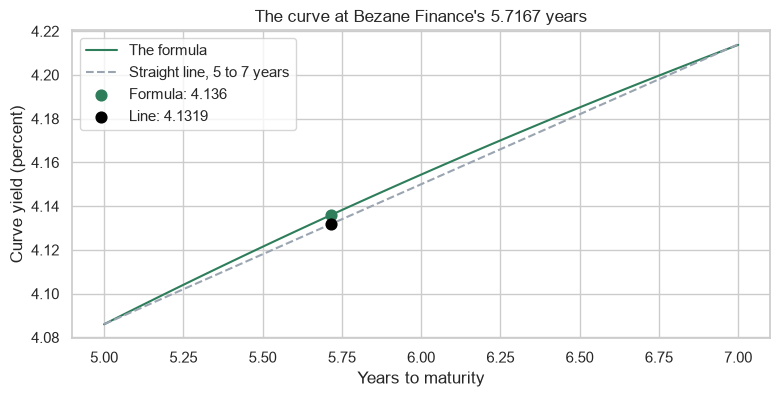

In [12]:
fine = np.linspace(5, 7, 100)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(fine, 3.55 + 1.05 * (1 - np.exp(-fine / 7)), label='The formula')
ax.plot([5, 7], curve_yields[5:7], linestyle='--', label='Straight line, 5 to 7 years')
ax.scatter([years], [curve_formula_pct], s=60, zorder=3, label=f'Formula: {curve_formula_pct}')
ax.scatter([years], [curve_line_pct], s=60, color='black', zorder=3,
           label=f'Line: {curve_line_pct:.4f}')
ax.set_title("The curve at Bezane Finance's 5.7167 years")
ax.set_xlabel('Years to maturity')
ax.set_ylabel('Curve yield (percent)')
ax.legend()
plt.show()

The line runs just under the bending curve, as in notebook 11's smooth-against-straight chart.

### The Spread, From the Formula

Q. Bezane's yield less the formula's curve, in bp?

In [13]:
# the gap in percent, times 100 basis points per percent
print(f"{(bond['yield_pct'] - curve_formula_pct) * 100:.6f} bp; the file says {bond['oas']}")

147.000000 bp; the file says 147


147 to the last printed digit.

**Excel side by side.** Years in G2; the curve's tenors in A2:A11 and yields in B2:B11.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The straight line</td><td align="left"><code>bondmath.interpolate_yield(years, curve_tenors, curve_yields)</code></td><td align="left">notebook 11's <code>FORECAST.LINEAR</code> with <code>INDEX</code> and <code>MATCH</code></td><td align="left">4.131866666666667</td></tr>
<tr><td align="left">The formula</td><td align="left"><code>round(3.55 + 1.05 * (1 - math.exp(-years / 7)), 3)</code></td><td align="left"><code>=ROUND(3.55+1.05*(1-EXP(-G2/7)),3)</code></td><td align="left">4.136</td></tr>
</table>
<br clear="left">

**The file read its curve from the formula at the bond's own years, rounded to 3 decimals: 147 to the last digit.**

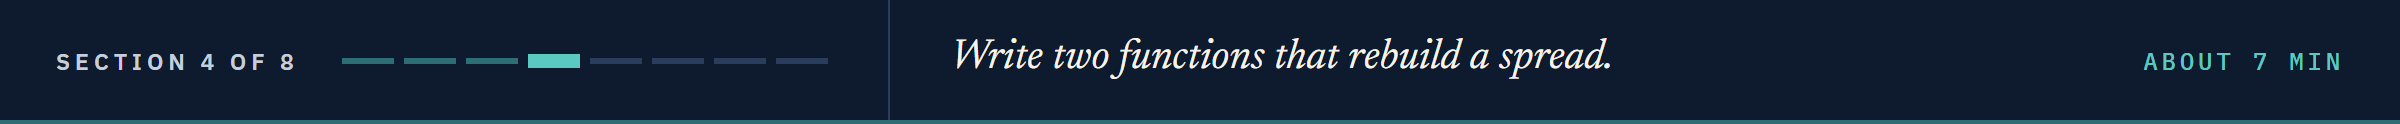

## 12.4 Two Functions, Docstring First

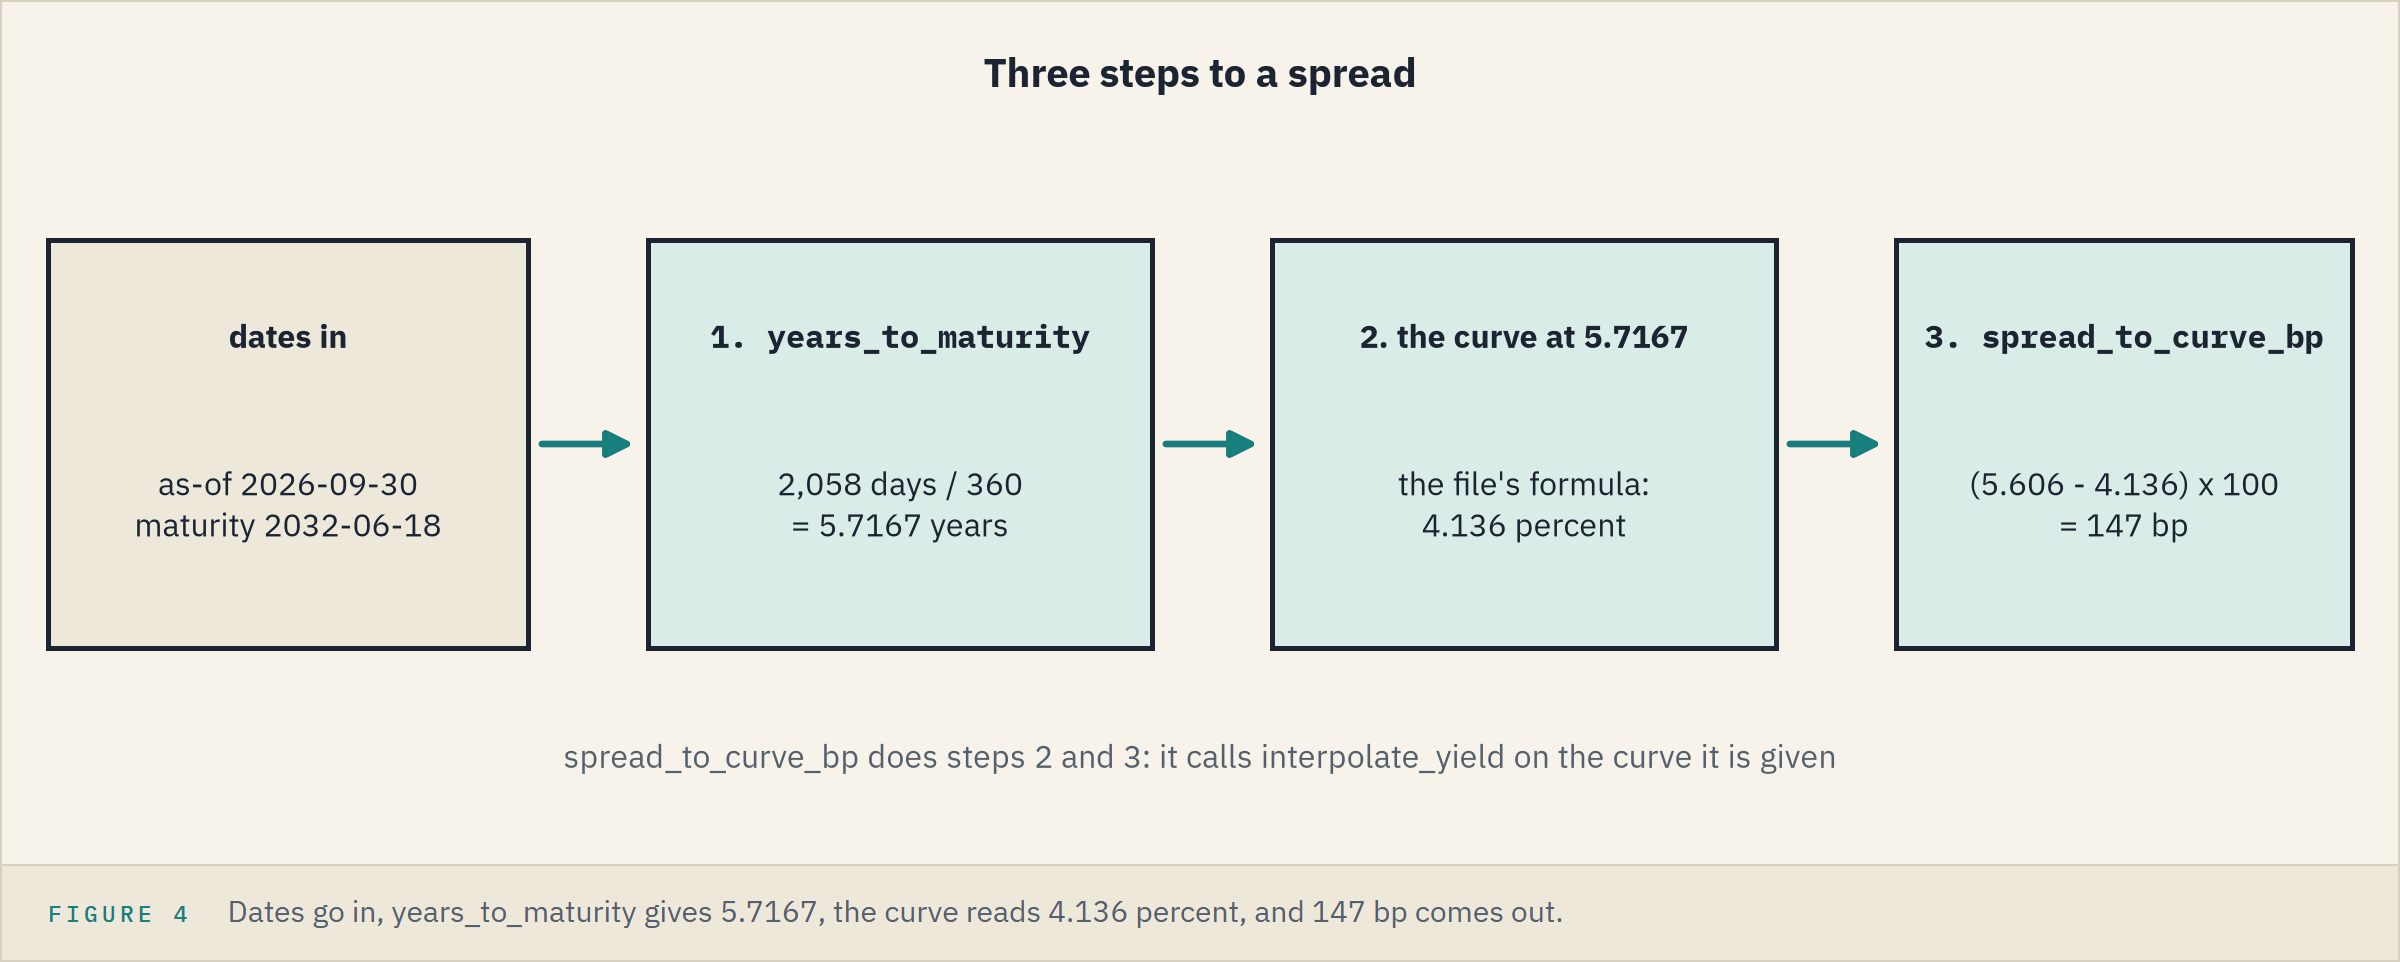

Three steps make a spread: dates to years, years to a curve yield, the difference times 100.
Two functions do them, written the module's way: docstring first, then the code.

### Write `years_to_maturity`

Q. Add `years_to_maturity` to the module. Read the docstring before you run the cell.

In [14]:
%%writefile -a bondmath.py


def years_to_maturity(settlement: date, maturity: date) -> float:
    """Years from settlement to maturity on the US 30/360 basis.

    Units: dates in, years out. Convention: days_30_360(settlement, maturity) / 360, the rule the
    holdings file used to read the curve. Excel: =YEARFRAC(settlement, maturity, 0)
    """
    # stop on dates in the wrong order
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # 30/360 days over a 360-day year
    return days_30_360(settlement, maturity) / 360

Appending to bondmath.py


### Three Cases

Q. Reload the module and count three pairs of dates in 30/360 days.

In [15]:
import importlib
from datetime import date

importlib.reload(bondmath)
# exactly ten years, Bezane Finance, and a start on the last day of February
cases = [(date(2026, 9, 30), date(2036, 9, 30)), (date(2026, 9, 30), date(2032, 6, 18)),
         (date(2027, 2, 28), date(2031, 8, 31))]
for start, end in cases:
    print(start, 'to', end, round(bondmath.years_to_maturity(start, end) * 360), 'days')

2026-09-30 to 2036-09-30 3600 days
2026-09-30 to 2032-06-18 2058 days
2027-02-28 to 2031-08-31 1621 days


1621: notebook 07's February rule makes the 28 February start the 30th and leaves the 31st alone.
That is `YEARFRAC`'s count; `DAYS360` gave 1620.

### Dates the Wrong Way Round

Q. What happens when maturity comes first?

In [16]:
# maturity before settlement
bondmath.years_to_maturity(date(2032, 6, 18), date(2026, 9, 30))

ValueError: settlement 2032-06-18 must be before maturity 2026-09-30

It refuses: a negative number of years would read the curve without complaint.

### Write `spread_to_curve_bp`

Q. Add `spread_to_curve_bp`. The curve comes in as two lists, so any curve will do.

In [17]:
%%writefile -a bondmath.py


def spread_to_curve_bp(yield_pct: float, years: float, curve_tenors: list[float],
                       curve_yields_pct: list[float]) -> float:
    """Yield spread over a curve at the bond's own maturity, in basis points.

    Units: yield_pct and curve yields in percent, years and tenors in years; the result is in bp.
    Convention: (yield_pct - the curve interpolated at `years`) x 100. A yield spread at the same
    maturity, not an option-adjusted spread from a spot curve.
    """
    # the curve yield at the bond's maturity
    curve_yield_pct = interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the gap in percent, times 100 basis points per percent
    return (yield_pct - curve_yield_pct) * 100

Appending to bondmath.py


### A Curve of One Point

The formula is not a table, but the function can still take it.
A curve of one point, the bond's own years and the formula's yield there, is flat at that yield everywhere: notebook 11's flat ends.

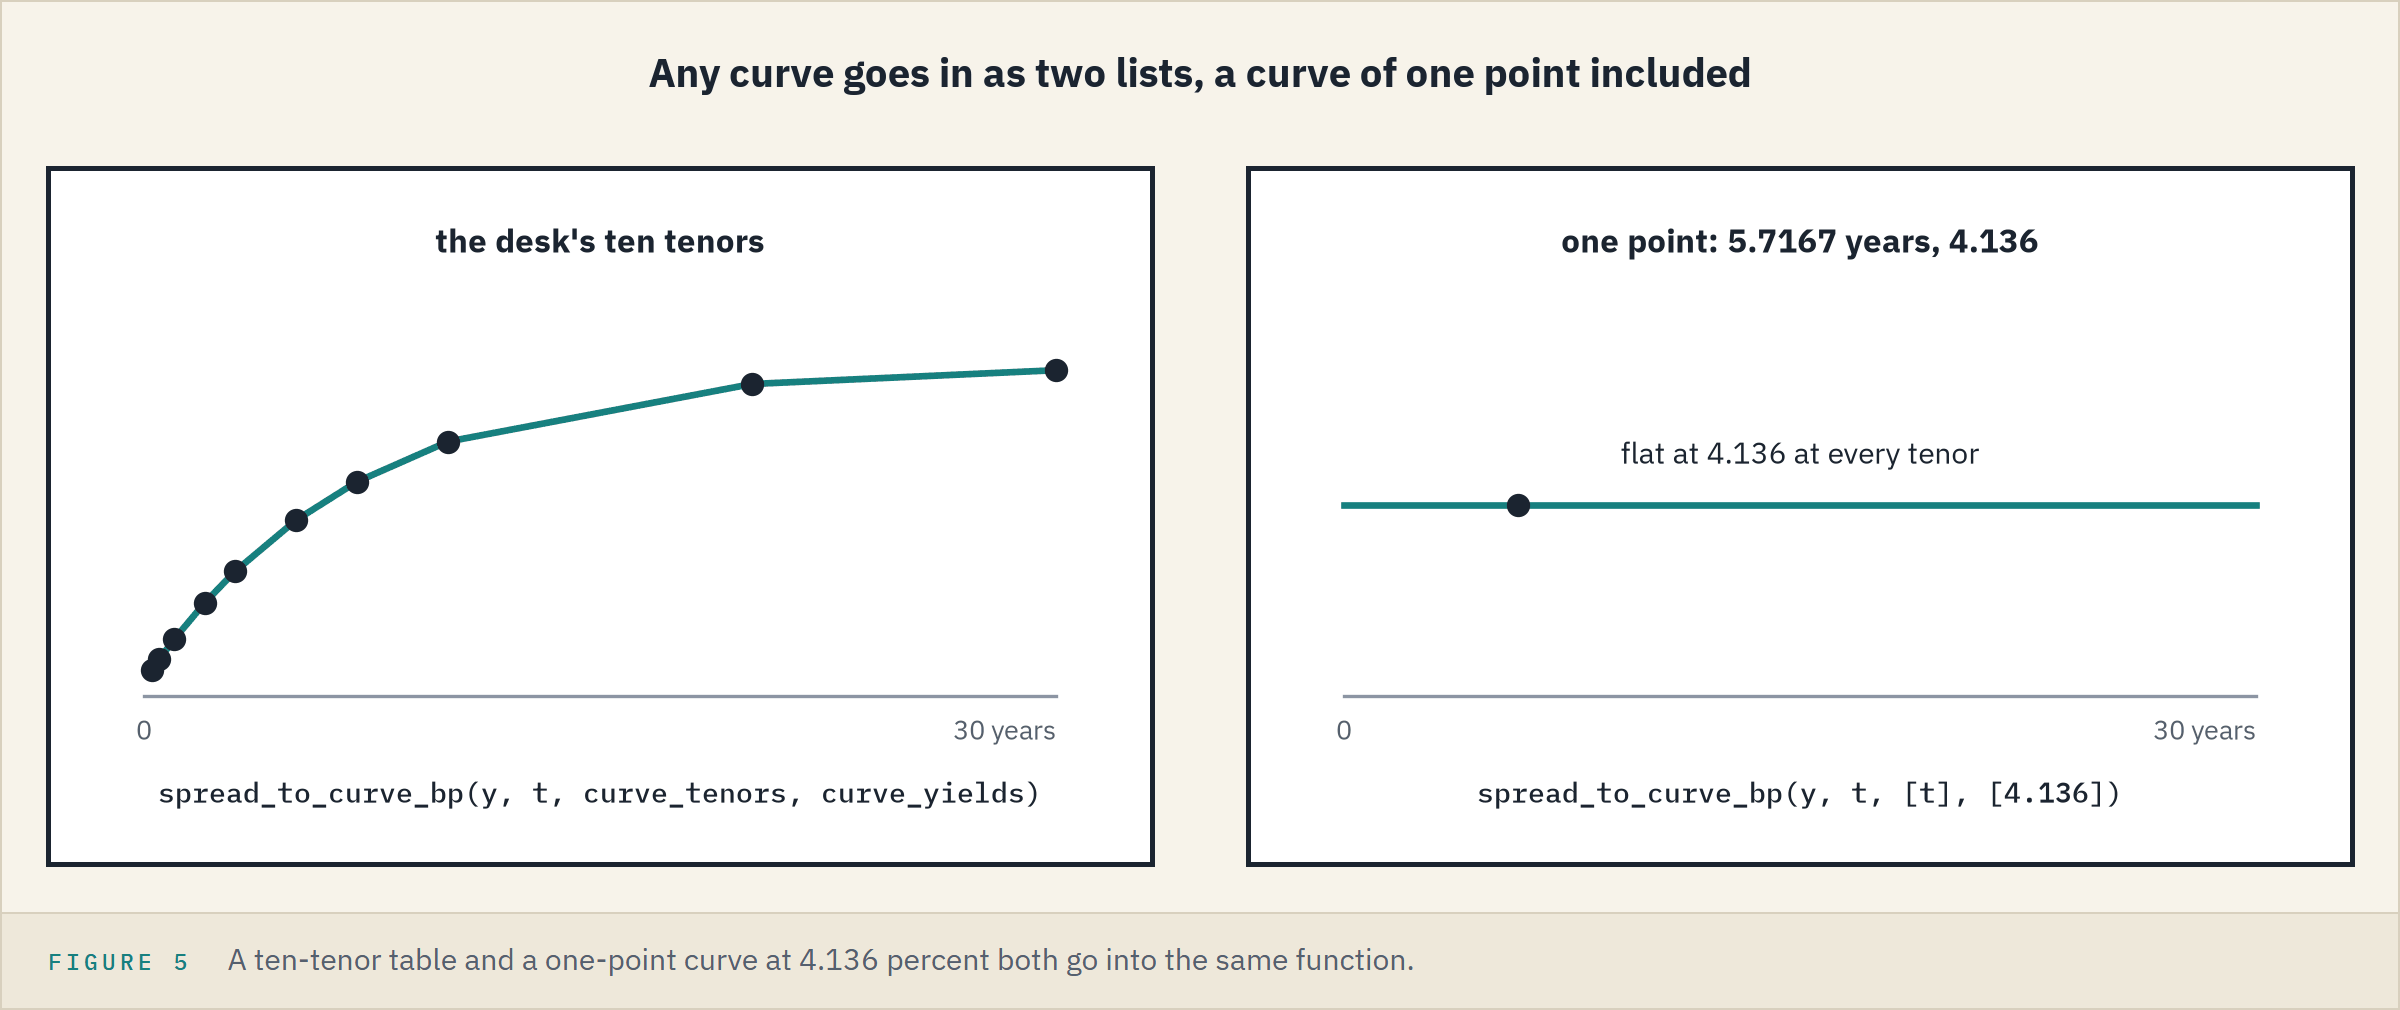

Q. Bezane's spread on a one-point curve?

In [18]:
importlib.reload(bondmath)
# one tenor, one yield: the formula's curve at the bond's own years
spread_bp = bondmath.spread_to_curve_bp(bond['yield_pct'], years, [years], [curve_formula_pct])
print(f'{spread_bp:.6f} bp')

147.000000 bp


### The Whole Book

Q. Rebuild the `oas` column for all 200 bonds, and stop if any bond misses.

In [19]:
holdings['curve_formula_pct'] = [round(3.55 + 1.05 * (1 - math.exp(-t / 7)), 3)
                                 for t in holdings['years']]
holdings['spread_formula_bp'] = [
    bondmath.spread_to_curve_bp(y, t, [t], [c])
    for y, t, c in zip(holdings['yield_pct'], holdings['years'], holdings['curve_formula_pct'])]
largest_miss = (holdings['spread_formula_bp'] - holdings['oas']).abs().max()
assert largest_miss < 1e-9, "a bond's spread does not reproduce its oas"
print(f'largest miss: {largest_miss:.1e} bp')

largest miss: 2.3e-13 bp


2.3e-13 bp is float rounding, as in Course 1's 0.1 + 0.2: zero for any desk.

### The Book Against the File's Curve

Q. Draw every bond's yield against the formula's curve, with Bezane's spread as an arrow.

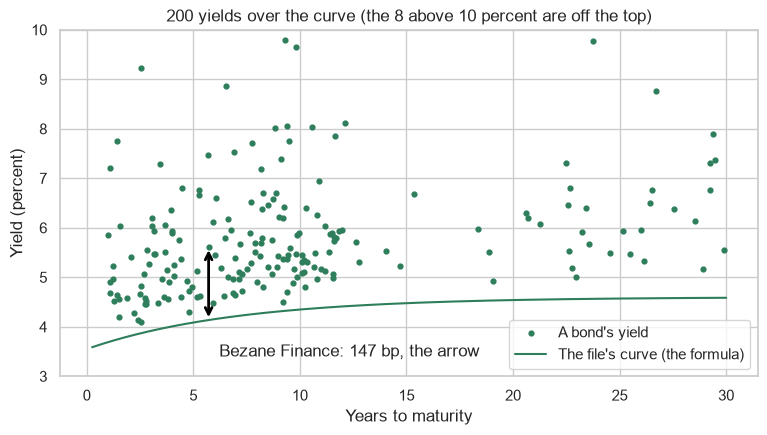

In [20]:
fine = np.linspace(0.25, 30, 300)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(holdings['years'], holdings['yield_pct'], s=12, label="A bond's yield")
ax.plot(fine, 3.55 + 1.05 * (1 - np.exp(-fine / 7)), label="The file's curve (the formula)")
# arrowstyle '<->' puts a head at both ends, linewidth sets the thickness: its length is the spread
ax.annotate('', xy=(years, bond['yield_pct']), xytext=(years, curve_formula_pct),
            arrowprops={'arrowstyle': '<->', 'color': 'black', 'linewidth': 2})
ax.text(years + 0.5, 3.4, 'Bezane Finance: 147 bp, the arrow')
ax.set_ylim(3, 10)
ax.set_title('200 yields over the curve (the 8 above 10 percent are off the top)')
ax.set_xlabel('Years to maturity')
ax.set_ylabel('Yield (percent)')
ax.legend(loc='lower right')
plt.show()

Each bond's height above the line is its spread.

**Excel side by side.** The yield in F2 is typed in percent, as in the file, and no Excel function receives it, so there is no `/100`.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Spread to the formula, bp</td><td align="left"><code>bondmath.spread_to_curve_bp(y, t, [t], [c])</code></td><td align="left"><code>=(F2-J2)*100</code>, the formula's curve in J2</td><td align="left">146.99999999999997</td></tr>
</table>
<br clear="left">

**Two functions rebuild the `oas` column for all 200 bonds, to 2.3e-13 of a basis point.**

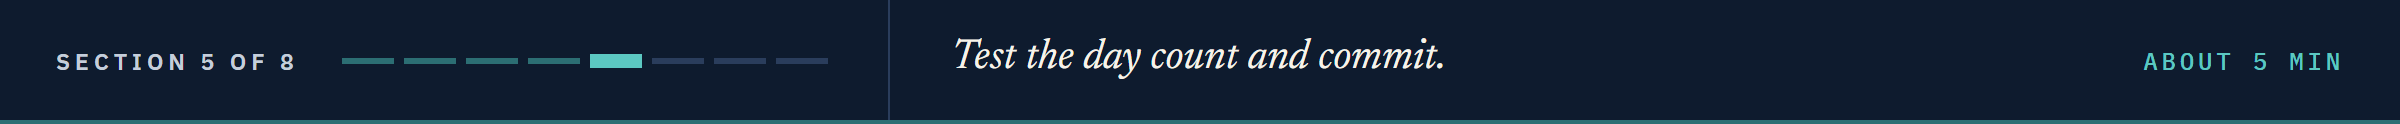

## 12.5 Tests From Excel, Then Commit

### Test the Day Count

Each case is a 30/360 count Excel's `YEARFRAC(settlement, maturity, 0)` x 360 returned for the same dates (the course's Excel run of 4 October 2026).
The cell starts with `import math`: today's third test reads the curve's formula.

In [21]:
%%writefile -a test_bondmath.py


import math


def test_years_to_maturity_cases():
    # (settlement, maturity, 30/360 days); each was checked in Excel as YEARFRAC(settlement, maturity, 0) x 360
    cases = [
        (date(2026, 9, 30), date(2036, 9, 30), 3600),  # exactly ten years
        (date(2026, 9, 30), date(2032, 6, 18), 2058),  # the first bond in holdings.csv
        (date(2027, 2, 28), date(2031, 8, 31), 1621),  # the 31st end stays 31 after a 28 February start
    ]
    for settlement, maturity, days in cases:
        assert bondmath.years_to_maturity(settlement, maturity) == pytest.approx(days / 360, abs=1e-12)

Appending to test_bondmath.py


### Test a Case Worked by Hand

Six years is halfway from 5 to 7, so the curve is the average of 4.086 and 4.214, 4.150, and a 5 percent yield is 85.0 bp over it.
`CURVE_TENORS` and `CURVE_YIELDS_PCT` came into the test file with notebook 11.

In [22]:
%%writefile -a test_bondmath.py


def test_spread_to_curve_known_case():
    # a 5 percent yield at 6 years: halfway between the 5-year (4.086) and 7-year (4.214) points
    curve_at_6_years = 4.086 + (4.214 - 4.086) * (6 - 5) / (7 - 5)
    expected_bp = (5.0 - curve_at_6_years) * 100
    result = bondmath.spread_to_curve_bp(5.0, 6.0, CURVE_TENORS, CURVE_YIELDS_PCT)
    assert result == pytest.approx(expected_bp, abs=1e-9)

Appending to test_bondmath.py


### Test Five Rows of the File

Five bonds typed in with their CUSIPs; a failing row names its CUSIP.

In [23]:
%%writefile -a test_bondmath.py


def test_spread_reproduces_oas_rows():
    # five rows of holdings.csv (as of 2026-09-30): cusip, maturity, yield_pct, oas
    rows = [
        ("99080CAE8", date(2032, 6, 18), 5.606, 147),
        ("99049XAE2", date(2029, 4, 17), 9.22, 535),
        ("99039NAC0", date(2030, 6, 3), 5.509, 153),
        ("99039NAG1", date(2053, 4, 9), 6.756, 218),
        ("99034IAD4", date(2036, 4, 5), 5.6, 127),
    ]
    for cusip, maturity, yield_pct, oas in rows:
        years = bondmath.years_to_maturity(date(2026, 9, 30), maturity)
        # the file was built on the curve's formula at the bond's own maturity, rounded to 3 decimals,
        # so a one-point curve at exactly that maturity gives the file's spread
        curve_yield_pct = round(3.55 + 1.05 * (1 - math.exp(-years / 7)), 3)
        result = bondmath.spread_to_curve_bp(yield_pct, years, [years], [curve_yield_pct])
        assert result == pytest.approx(oas, abs=1e-9), cusip

Appending to test_bondmath.py


### Run the Tests

In [24]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...................................                                      [100%]
35 passed in 0.50s



32 from notebooks 01 to 11, and today's three.

### Read the Diff, Then Commit

In [25]:
!git -C "{work}" diff --stat
!git -C "{work}" add bondmath.py test_bondmath.py
!git -C "{work}" commit -q -m "Notebook 12: years_to_maturity and spread_to_curve_bp"

 bondmath.py      | 27 +++++++++++++++++++++++++++
 test_bondmath.py | 40 ++++++++++++++++++++++++++++++++++++++++
 2 files changed, 67 insertions(+)


### When Did the Tests Arrive?

As in notebook 09, `--` and a file name keep only the commits that changed that file; notebook 05's `--decorate` shows the tags.

In [26]:
!git -C "{work}" log --oneline --decorate -- test_bondmath.py

4c7dcbc (HEAD -> main) Notebook 12: years_to_maturity and spread_to_curve_bp
10f4dad Notebook 11: interpolate_yield
90faa12 (tag: week2) Notebook 10: convexity
5fcb7c6 Notebook 09: macaulay_duration, modified_duration, and dv01
20b3546 Notebook 08: price, dirty_price, and yield_to_maturity
98124d3 Notebook 07: days_30_360, coupon_period_days, and accrued_interest
9fe8f04 Notebook 06: add_months, coupon_dates, and a .gitignore
322960d (tag: week1) Notebook 05: tests of par pricing and of price against yield
7147a11 Notebook 04: yield_from_price
3f57cac Notebook 03: convert_yield
408a678 Notebook 02: cash_flows and price_from_yield
d029474 Notebook 01: future_value and present_value


All twelve: every notebook added tests.
The same command with `bondmath.py` leaves out notebook 05, which added tests only.

### How Much Since the End of Week 2?

`git diff --stat` with a tag compares that commit with the files now.

In [27]:
!git -C "{work}" diff --stat week2

 bondmath.py      | 57 ++++++++++++++++++++++++++++++++++++++++++++++
 test_bondmath.py | 69 ++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 126 insertions(+)


Notebooks 11 and 12, the first two of week 3.

**35 tests pass, and the history says when every test arrived.**

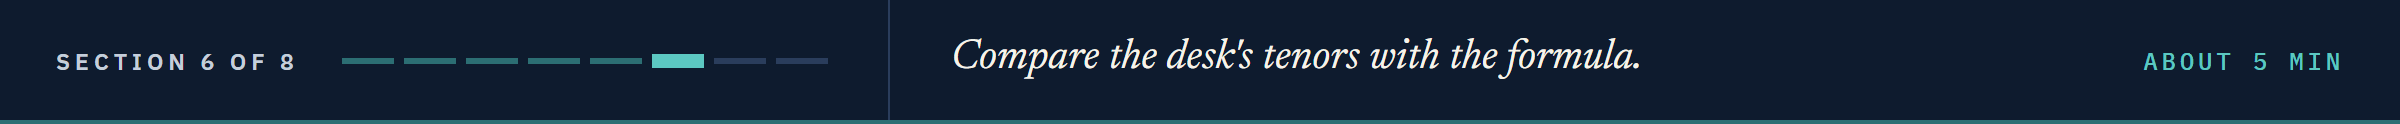

## 12.6 The Desk's Ten-Tenor Table, and the Gap

### Every Spread on the Table

Q. Read the desk's ten tenors with straight lines for all 200 bonds.

In [28]:
holdings['curve_table_pct'] = [bondmath.interpolate_yield(t, curve_tenors, curve_yields)
                               for t in holdings['years']]
holdings['spread_table_bp'] = [bondmath.spread_to_curve_bp(y, t, curve_tenors, curve_yields)
                               for y, t in zip(holdings['yield_pct'], holdings['years'])]
# table minus file: positive where the straight line gives the larger spread
holdings['gap_bp'] = holdings['spread_table_bp'] - holdings['oas']
print(f"Bezane Finance on the table: {holdings.loc[0, 'spread_table_bp']:.2f} bp")

Bezane Finance on the table: 147.41 bp


### How Big Are the Gaps?

**Predict 3**

Q. Notebook 11 averaged the line's distance below the formula over an even grid from 0.25 to 30 years: 1.01 bp. Averaged over the 200 bonds, at their own maturities, the size of the gap is:

A) smaller: most bonds mature where the tenors sit close together

B) about the same: the same curve and the same straight lines

C) larger: the file's rounding adds to every gap

In [29]:
size = holdings['gap_bp'].abs()
print(f'average {size.mean():.2f} bp, largest {size.max():.2f} bp')
print(f"under 10 years: {(holdings['years'] < 10).sum()} of 200 bonds")
print(f"table spread larger: {(holdings['gap_bp'] > 0).sum()} of 200 bonds")
holdings.loc[size.idxmax(), ['cusip', 'issuer', 'years', 'curve_formula_pct', 'curve_table_pct',
                             'gap_bp']]

average 0.64 bp, largest 3.35 bp
under 10 years: 130 of 200 bonds
table spread larger: 196 of 200 bonds


cusip                       99069RAD2
issuer               Feskovar Devices
years                       14.141667
curve_formula_pct               4.461
curve_table_pct               4.42752
gap_bp                          3.348
Name: 66, dtype: object

A: 0.64 bp, because 130 bonds mature inside 10 years, where tenors sit close, while most of notebook 11's grid lies beyond 10.
The largest is Feskovar Devices at 14.14 years, between the 10-year and 20-year tenors.

### Where Along the Curve

Q. Chart each bond's gap against its years.

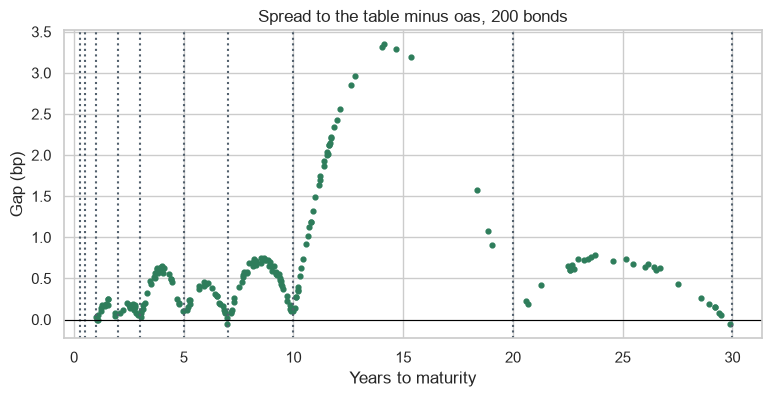

In [30]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(holdings['years'], holdings['gap_bp'], s=12)
# the ten tenors, where the line touches the curve, and zero
for tenor in curve_tenors:
    ax.axvline(tenor, color='#52606D', linestyle=':')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Spread to the table minus oas, 200 bonds')
ax.set_xlabel('Years to maturity')
ax.set_ylabel('Gap (bp)')
plt.show()

The gaps fall to zero at the tenors and rise between them, most from 10 to 20 years: tenors far apart, on a curve that still bends.
The line sits under a curve that bends this way, and a lower curve yield leaves a larger spread.
The four bonds below zero lie within weeks of a tenor and at most 0.06 bp under, where the rounding decides the sign.

### The Other Count of Years

**Predict 4**

Q. Rerun the formula, rounding and all, on actual days over 365. The largest miss against `oas` is:

A) thousandths of a bp: the years barely move

B) about a tenth of a bp: the rounded curve moves in whole steps or not at all

C) about 3 bp, the size of the table's gaps

In [31]:
# the formula and its rounding again, on actual days over 365
actual_years = [(m - a).days / 365 for a, m in zip(holdings['as_of_date'], holdings['maturity'])]
actual_curve = pd.Series([round(3.55 + 1.05 * (1 - math.exp(-t / 7)), 3) for t in actual_years])
miss = ((holdings['yield_pct'] - actual_curve) * 100 - holdings['oas']).abs()
print(f'largest miss {miss.max():.3f} bp; {(miss > 1e-9).sum()} of 200 bonds miss')

largest miss 0.100 bp; 47 of 200 bonds miss


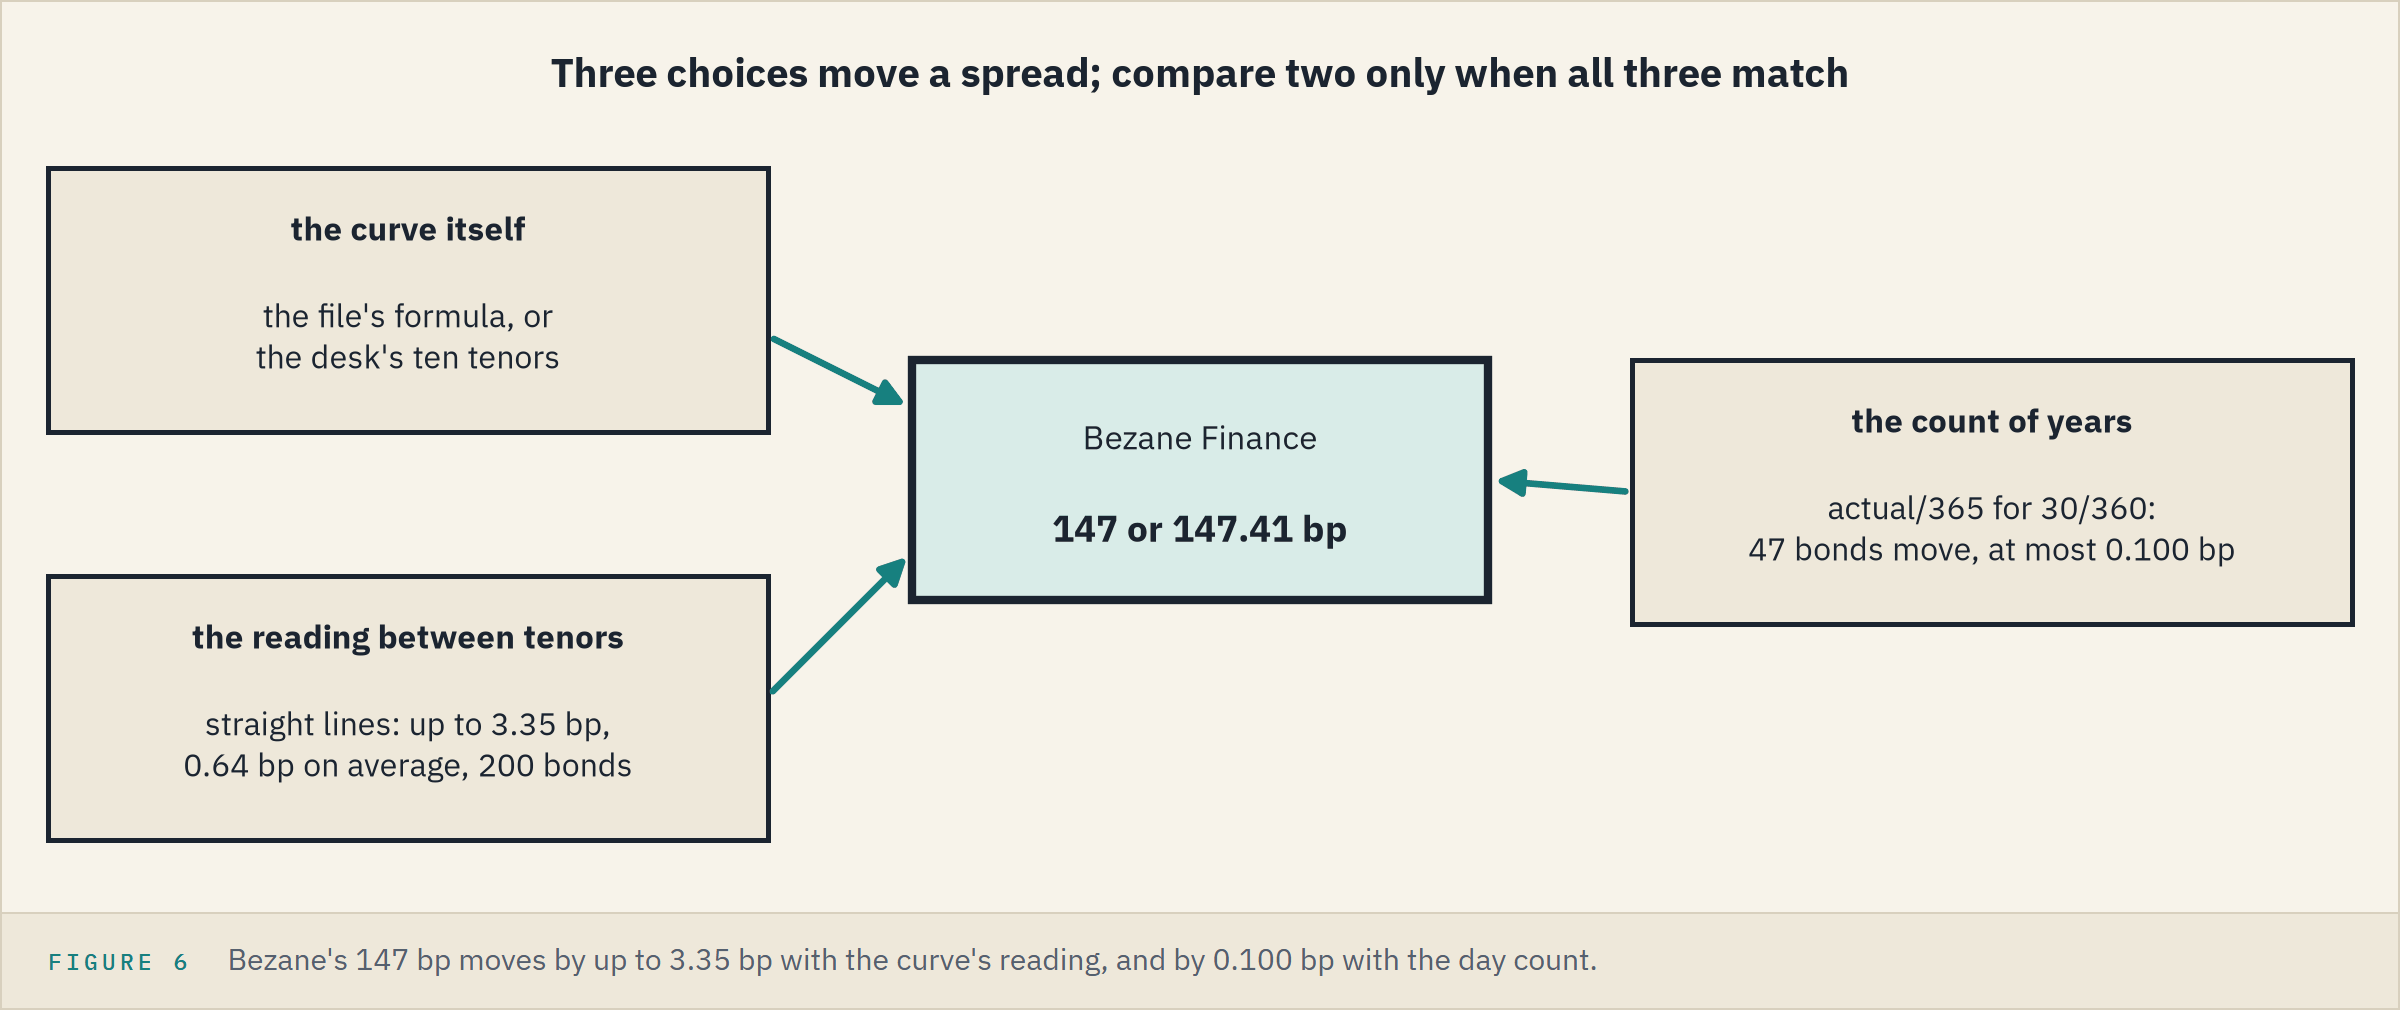

B: 0.100 bp on 47 bonds.
The rounded curve's smallest step is 0.001 percent, 0.1 bp, and a few days tips it or leaves it.

**Excel side by side.** The straight line in H2, from 12.3's table.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Spread to the table, bp</td><td align="left"><code>bondmath.spread_to_curve_bp(y, t, curve_tenors, curve_yields)</code></td><td align="left"><code>=(F2-H2)*100</code></td><td align="left">147.41333333333327</td></tr>
</table>
<br clear="left">

**The same bond on the same curve is 147 or 147.41: compare two spreads only when they share the curve, the reading between tenors, and the count of years.**

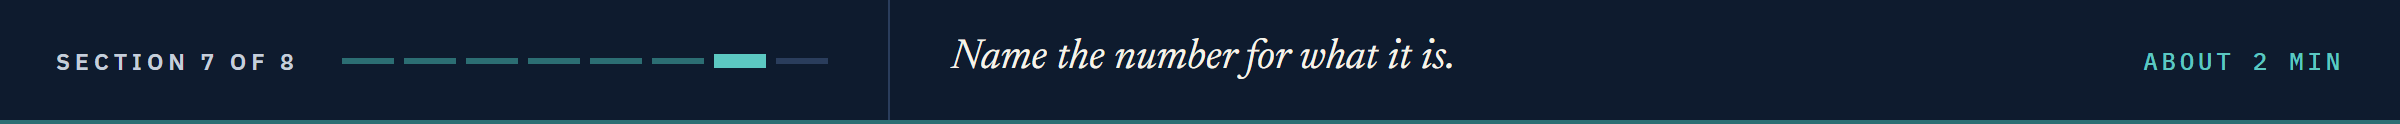

## 12.7 What to Call the Number

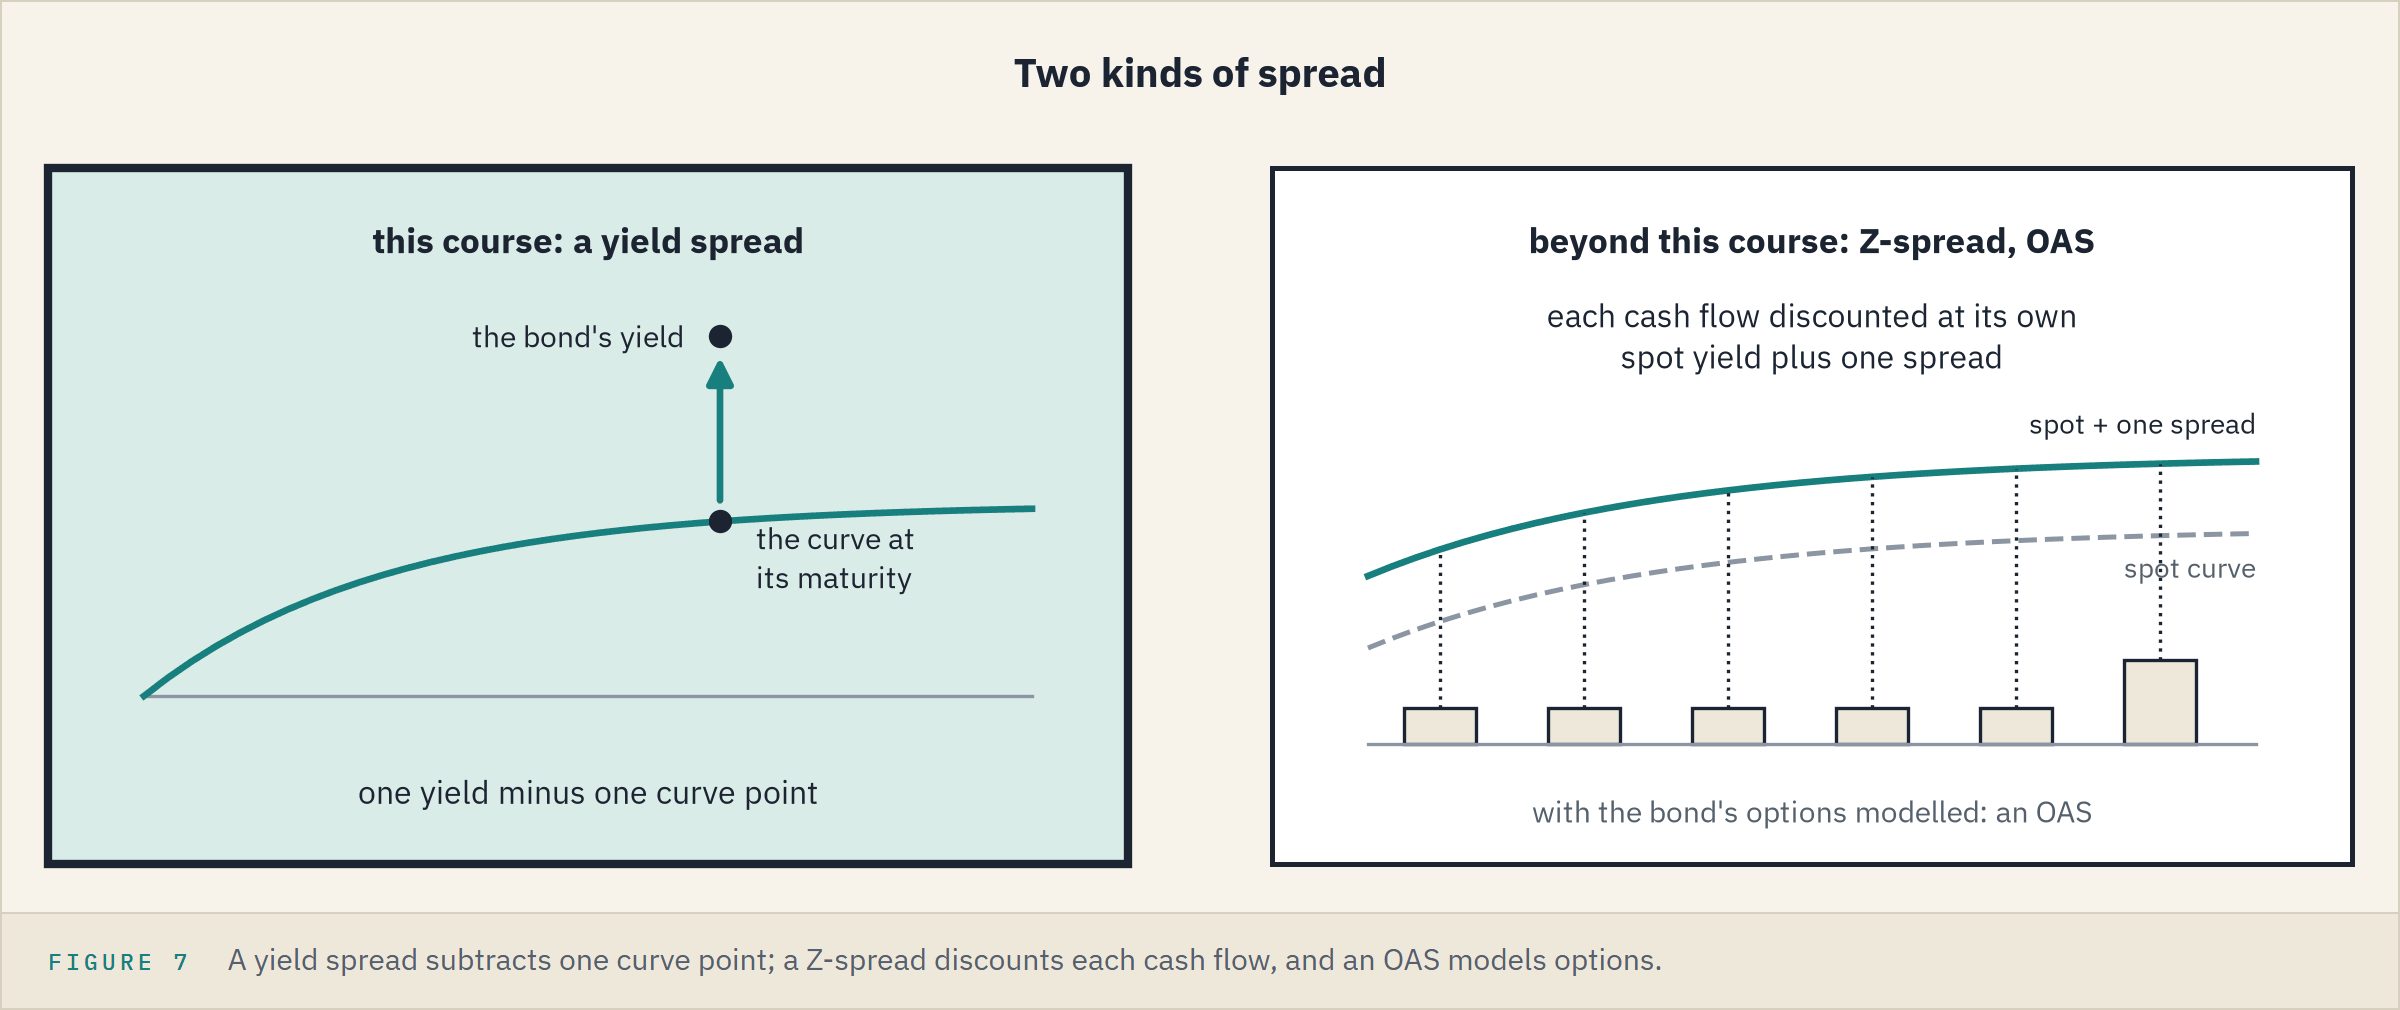

The file calls its column `oas`, short for option-adjusted spread.
The file built it as a **yield spread**: the bond's yield less the curve's yield at the same maturity.
Measured over a government curve, desks call this a **G-spread**.
A desk's OAS adds one spread to a **spot curve**, a zero-coupon yield for each date, and discounts every cash flow on it, with the bond's options valued by a model of moving rates.
For a bullet with no options, the OAS is close to the **Z-spread**: the same one spread, with no options to value.
Spot curves and Z-spreads are beyond this course.

### Three Numbers, Five Bonds

Q. The file's number and the two rebuilt, side by side for five bonds?

In [32]:
holdings[['issuer', 'oas', 'spread_formula_bp', 'spread_table_bp']].head().round(4)

,issuer,oas,spread_formula_bp,spread_table_bp
0,Bezane Finance,147,147.0,147.4133
1,Bezamyth Machinery,535,535.0,535.1542
2,Bezoquil Freight,153,153.0,153.5625
3,Bezoquil Freight,218,218.0,218.5985
4,Bezorin Finance,127,127.0,127.3713


**The course calls it `spread_to_curve_bp`, a yield spread at the bond's own maturity; the file keeps the name `oas`.**

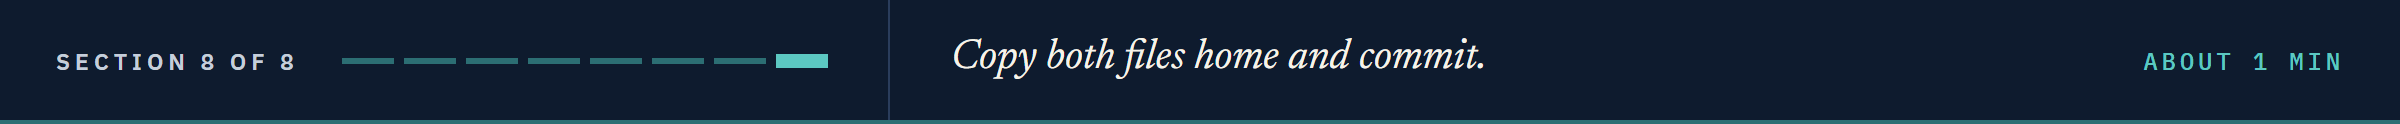

## Bring It Home

Copy today's two files into your own `my_bondmath` folder, then test and commit there.
The copy replaces your files: anything of your own must be in the work folder first.
In PowerShell, with the course's `.venv` active, and your eight characters from the setup cell in place of `k4w7q2xr`:

```powershell
Set-Location "$HOME\projects\my_bondmath"
$work = "$env:TEMP\pfi_course2_12_k4w7q2xr"
Copy-Item "$work\bondmath.py", "$work\test_bondmath.py", "$work\.gitignore" .
python -m pytest -q
git diff --stat
git add bondmath.py test_bondmath.py
git commit -m "Notebook 12: years_to_maturity and spread_to_curve_bp"
git log --oneline -- test_bondmath.py
git diff --stat week2
```

If `week2` is unknown, tag notebook 10's commit: `git tag week2` followed by its hash.
In Colab, download the two files from the work folder in the file browser.
The work folder stays in your temp folder.

## You Can Now

By the end of this notebook, you can:

* Say what a spread to the curve measures, in bp.
* Count years to maturity on 30/360 with `years_to_maturity`, as Excel's `YEARFRAC` with basis 0 does.
* Compute a spread with `spread_to_curve_bp` on any curve, a one-point curve included.
* Rebuild the file's `oas` column from the curve's formula.
* Measure how far the reading between tenors moves a spread, and say when two spreads compare.
* Call the number a yield spread, and list the commits that changed one file.

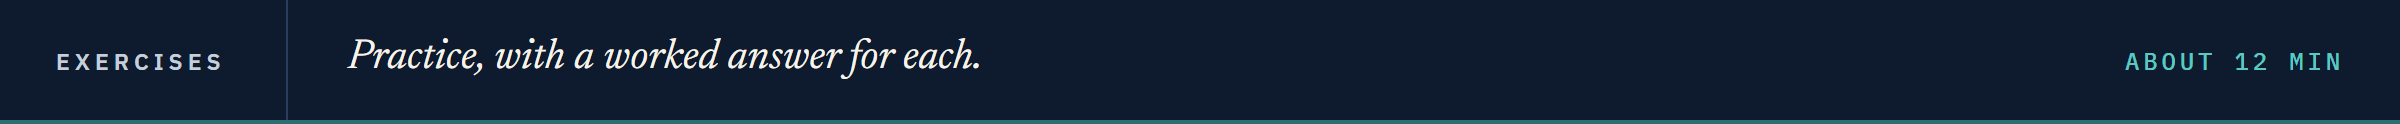

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

The exercises use twenty bonds from `benchmark.csv` the book does not hold, built on the same curve.
Replace each `...` with your own code, then run the cell.
Run the next two cells first: `check`, and the twenty bonds.

In [33]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [34]:
# every 30th benchmark bond the book does not hold, twenty in all ([::30] steps 30 rows at a time)
benchmark = pd.read_csv('benchmark.csv')
not_held = benchmark[~benchmark['cusip'].isin(holdings['cusip'])]
twenty = not_held.iloc[::30].head(20).reset_index(drop=True)
twenty['as_of_date'] = pd.to_datetime(twenty['as_of_date']).dt.date
twenty['maturity'] = pd.to_datetime(twenty['maturity']).dt.date
ratings = pd.read_csv('ratings.csv')
twenty[['cusip', 'issuer', 'rating', 'maturity', 'yield_pct', 'oas']].head()

,cusip,issuer,rating,maturity,yield_pct,oas
0,99001BAB2,Quorvane Energy,BBB,2035-08-08,5.524,122
1,99008IAD6,Osmere Chemicals,BBB-,2032-07-21,5.252,111
2,99016QAG1,Corvolvey Systems,BB+,2028-08-11,5.075,128
3,99025ZAD7,Kezazor Logistics,A,2028-03-14,4.457,71
4,99032GAB4,Queloquil Health,BBB-,2035-02-01,6.031,175


### Exercise 1

Q. Add `years` and `spread_table_bp` columns to `twenty` with today's two functions, and `assert` that the formula's one-point curve reproduces every `oas` within 1e-9 bp. Store the first bond's `spread_table_bp` in `ex1_first_bp` and the largest `spread_table_bp` minus `oas` in `ex1_largest_gap_bp`.

In [35]:
ex1_first_bp = ...
ex1_largest_gap_bp = ...
check('Exercise 1 first spread', ex1_first_bp, 122.71185185185188)
check('Exercise 1 largest gap', ex1_largest_gap_bp, 1.9533333333333616)

Exercise 1 first spread: not attempted yet
Exercise 1 largest gap: not attempted yet


### Exercise 2

Q. Join `ratings` to `twenty` on `rating`, then count the bonds and take the mean `spread_table_bp` of each bucket, in rating order. Use Exercise 1's `spread_table_bp`. Store the number of buckets in `ex2_buckets` and the BBB mean in `ex2_bbb_mean_bp`, and describe the table in one sentence, with no view on any bond.

In [36]:
ex2_buckets = ...
ex2_bbb_mean_bp = ...
check('Exercise 2 buckets', ex2_buckets, 5)
check('Exercise 2 BBB mean', ex2_bbb_mean_bp, 151.46441666666666)

Exercise 2 buckets: not attempted yet
Exercise 2 BBB mean: not attempted yet


### Exercise 3

Q. Write `spread_change_bp(old_spread_bp, new_spread_bp)`, new minus old in bp, docstring first, with a test `test_spread_change_bp_known_case` worked by hand. Append each in its cell below, run the tests with 12.5's cell, reload, and store the change of Feskovar Devices' `99069RAD2` from its `oas` to its spread on the table in `ex3_change`.

In [37]:
%%writefile -a bondmath.py


# Exercise 3: write spread_change_bp(old_spread_bp, new_spread_bp) below this line

Appending to bondmath.py


In [38]:
%%writefile -a test_bondmath.py


# Exercise 3: write test_spread_change_bp_known_case() below this line

Appending to test_bondmath.py


In [39]:
ex3_change = ...
check('Exercise 3 Feskovar change', ex3_change, 3.34800000000007)

Exercise 3 Feskovar change: not attempted yet


### Exercise 4: AI check

You gave an AI assistant `spread_to_curve_bp`'s docstring and asked for the function.
This came back, written for this course in an assistant's style: it runs, and it breaks one convention.

In [40]:
def assistant_spread_to_curve_bp(yield_pct, years, curve_tenors, curve_yields_pct):
    """Yield spread over a curve at the bond's own maturity, in basis points."""
    # the curve yield at the bond's own maturity
    curve_yield_pct = bondmath.interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the spread between the bond's yield and the curve
    return yield_pct - curve_yield_pct

Q. Test it against Excel's `=(F2-H2)*100` for the first five bonds.

In [41]:
# Excel's spreads to the table, from the course's Excel run of the first five holdings rows
excel_spread_bp = [147.41333333333327, 535.1541666666668, 153.5625, 218.5984999999999,
                   127.37129629629624]
for i, expected in enumerate(excel_spread_bp):
    row = holdings.loc[i]
    result = assistant_spread_to_curve_bp(row['yield_pct'], row['years'],
                                          curve_tenors, curve_yields)
    assert abs(result - expected) < 1e-6, f"{row['cusip']}: {result:.6f}, Excel {expected}"
print("all five match Excel's spread in bp")

AssertionError: 99080CAE8: 1.474133, Excel 147.41333333333327

Q. Fix the function, run both cells until all five match, and store Bezane Finance's spread in `ex4_first_bp`.

In [42]:
ex4_first_bp = ...
check('Exercise 4 Bezane Finance', ex4_first_bp, 147.41333333333327)

Exercise 4 Bezane Finance: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Where 147 comes from</td><td align="left">5.606 less the formula's 4.136 at 5.7167 years, times 100</td></tr>
<tr><td align="left">All 200 rebuilt</td><td align="left">to 2.3e-13 bp, two functions, 35 tests</td></tr>
<tr><td align="left">Our ten-tenor curve</td><td align="left">up to 3.35 bp more, 0.64 on average</td></tr>
<tr><td align="left">What to call it</td><td align="left">a yield spread to the curve (a G-spread), not an OAS</td></tr>
</table>
<br clear="left">

Be proud: you can say exactly how a spread on someone else's file was built.

Next is Spread Duration and DTS: what the price does when the spread moves.

[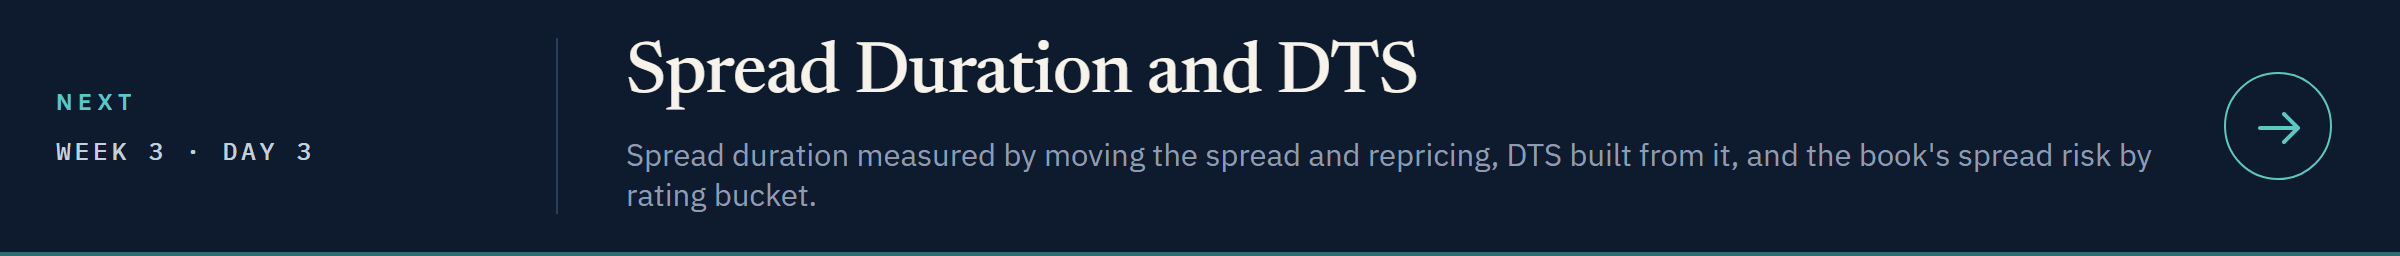](../day3/13_spread_duration_and_dts.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day3/13_spread_duration_and_dts.ipynb)